# 2015 — U-Net: Image Segmentation

**Paper:** Olaf Ronneberger, Philipp Fischer & Thomas Brox, *"U-Net: Convolutional Networks for Biomedical Image Segmentation"* (2015). Builds on Fully Convolutional Networks (Long et al., 2015).

Segmentation needs a label **for every pixel**. U-Net is an encoder–decoder:
- **contracting path:** convs and pooling capture *what* is in the image (context)
- **expanding path:** upsampling restores resolution
- **skip connections** concatenate encoder features into the decoder, restoring *where* (fine detail)

U-Net is still the standard in medical imaging, and it is the denoising backbone of most diffusion models (Stable Diffusion's UNet).

We generate a synthetic dataset: noisy images with random circles, squares and triangles, and the task is to label each pixel as background / circle / square / triangle.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


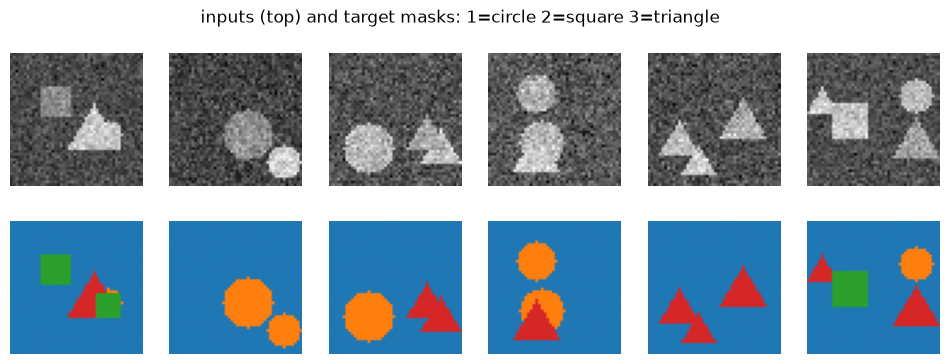

In [2]:
S = 48
yy, xx = np.mgrid[0:S, 0:S]
def make_sample(rng):
    img = np.zeros((S, S), np.float32); mask = np.zeros((S, S), np.int64)
    for _ in range(rng.integers(2, 5)):
        cls = rng.integers(1, 4); r = rng.integers(5, 10); cx, cy = rng.integers(r, S - r, 2)
        if cls == 1: m = (xx - cx) ** 2 + (yy - cy) ** 2 <= r ** 2
        elif cls == 2: m = (abs(xx - cx) <= r * 0.8) & (abs(yy - cy) <= r * 0.8)
        else: m = (yy - cy <= r * 0.8) & (yy - cy >= -r) & (abs(xx - cx) <= (yy - cy + r) * 0.6)
        img[m] = rng.uniform(0.5, 1.0); mask[m] = cls
    img += rng.normal(0, 0.15, img.shape).astype(np.float32)
    return img, mask

rng = np.random.default_rng(0)
data = [make_sample(rng) for _ in range(1200)]
X = torch.tensor(np.stack([d[0] for d in data]))[:, None].to(device)
Y = torch.tensor(np.stack([d[1] for d in data])).to(device)
Xtr, Ytr, Xte, Yte = X[:1000], Y[:1000], X[1000:], Y[1000:]
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for j in range(6):
    axes[0, j].imshow(Xtr[j, 0].cpu(), cmap="gray"); axes[1, j].imshow(Ytr[j].cpu(), cmap="tab10", vmin=0, vmax=9)
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.suptitle("inputs (top) and target masks: 1=circle 2=square 3=triangle"); plt.show()

In [3]:
def double_conv(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                         nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU())

class UNet(nn.Module):
    def __init__(self, n_classes=4, c=16, skips=True):
        super().__init__()
        self.skips = skips
        k = 2 if skips else 1
        self.d1, self.d2, self.d3 = double_conv(1, c), double_conv(c, 2 * c), double_conv(2 * c, 4 * c)
        self.bottom = double_conv(4 * c, 8 * c)
        self.u3 = nn.ConvTranspose2d(8 * c, 4 * c, 2, stride=2); self.c3 = double_conv(4 * c * k, 4 * c)
        self.u2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2); self.c2 = double_conv(2 * c * k, 2 * c)
        self.u1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2);     self.c1 = double_conv(c * k, c)
        self.out = nn.Conv2d(c, n_classes, 1)

    def forward(self, x):
        cat = lambda a, b: torch.cat([a, b], 1) if self.skips else a
        e1 = self.d1(x)                          # 48x48
        e2 = self.d2(F.max_pool2d(e1, 2))        # 24x24
        e3 = self.d3(F.max_pool2d(e2, 2))        # 12x12
        b = self.bottom(F.max_pool2d(e3, 2))     # 6x6
        x = self.c3(cat(self.u3(b), e3))         # skip connections: concatenate encoder features
        x = self.c2(cat(self.u2(x), e2))
        x = self.c1(cat(self.u1(x), e1))
        return self.out(x)

def mean_iou(pred, y, n=4):
    ious = [((pred == c) & (y == c)).sum().item() / max(1, ((pred == c) | (y == c)).sum().item()) for c in range(1, n)]
    return float(np.mean(ious))

def train(skips, epochs=12):
    seed_everything(0)
    m = UNet(skips=skips).to(device); opt = torch.optim.Adam(m.parameters(), lr=2e-3)
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(Xtr), device=device)
        for i in range(0, len(Xtr), 32):
            idx = perm[i:i + 32]
            loss = F.cross_entropy(m(Xtr[idx]), Ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    m.eval()
    with torch.no_grad(): pred = m(Xte).argmax(1)
    return m, pred

unet, pred = train(skips=True)
_, pred_noskip = train(skips=False)
print(f"mean IoU (circle/square/triangle) — U-Net: {mean_iou(pred, Yte):.3f} | same net without skip connections: {mean_iou(pred_noskip, Yte):.3f}")

mean IoU (circle/square/triangle) — U-Net: 0.920 | same net without skip connections: 0.840


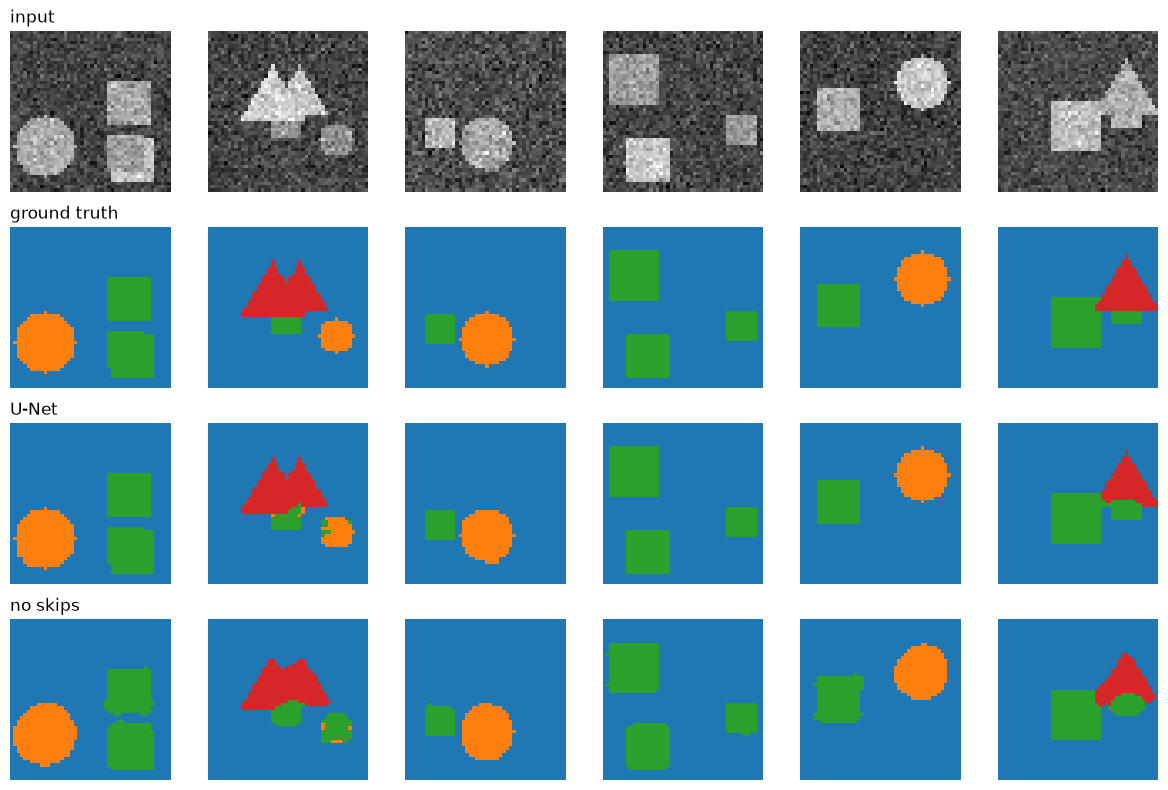

In [4]:
fig, axes = plt.subplots(4, 6, figsize=(12, 8))
for j in range(6):
    for r, (img, kw) in enumerate([(Xte[j, 0], dict(cmap="gray")), (Yte[j], dict(cmap="tab10", vmin=0, vmax=9)),
                                   (pred[j], dict(cmap="tab10", vmin=0, vmax=9)), (pred_noskip[j], dict(cmap="tab10", vmin=0, vmax=9))]):
        axes[r, j].imshow(img.cpu(), **kw); axes[r, j].axis("off")
for r, t in enumerate(["input", "ground truth", "U-Net", "no skips"]): axes[r, 0].set_title(t, loc="left")
plt.tight_layout(); plt.show()